# 03 — Entraînement : Pipeline Spark ML (sans fuite de données)

Entraînement sur `train` (steps 1–520), tous les choix sur `validation` (steps 521–631).
Le test n'est pas utilisé ici.

Variables du modèle principal, toutes connues au moment de la demande :

| Variable | Pourquoi |
|---|---|
| `amount` (en log) | montant demandé |
| `type` | type de transaction |
| heure tirée de `step` | moment de la demande |
| `oldbalanceDest` | solde du destinataire avant la transaction (l'opérateur gère les deux comptes) |

Variables exclues : soldes après transaction (`newbalanceOrig`, `newbalanceDest`, et les écarts calculés avec),
soldes de l'émetteur (connus au moment de la demande, mais dans PaySim ils encodent la règle du simulateur : le compte du fraudeur est vidé exactement), identifiants `nameOrig` / `nameDest`, `isFlaggedFraud`.

Étapes :
1. Poids de classe
2. Pipeline
3. Comparaison des modèles
4. Effet du poids des fraudes
5. Hyperparamètres (`ParamGridBuilder`, évalués sur la validation temporelle)
6. Choix du seuil
7. Sauvegarde

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("fraude-03-entrainement")
         .master("spark://spark-master:7077")
         .config("spark.driver.host", "spark-master")
         .config("spark.driver.memory", "2g")
         .config("spark.executor.memory", "2g")
         .config("spark.sql.shuffle.partitions", "18")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", "file:///tmp/spark-events")
         .getOrCreate())

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/27 23:49:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, SQLTransformer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder
from pyspark.ml.functions import vector_to_array
import pandas as pd
import matplotlib.pyplot as plt

train = spark.read.parquet("/workspace/data/ml/train.parquet")
validation = spark.read.parquet("/workspace/data/ml/validation.parquet")

## 1. Poids de classe

Formule « balanced » : `poids = total / (2 × effectif de la classe)`, calculée sur l'entraînement.
On l'exprime ensuite comme un rapport : une transaction normale vaut 1, une fraude vaut `rapport`.

In [3]:
nb_total = train.count()
nb_fraudes = train.filter("label = 1").count()
nb_normales = nb_total - nb_fraudes

rapport = nb_normales / nb_fraudes
print("Entraînement :", nb_total, "lignes,", nb_fraudes, "fraudes")
print("Rapport balanced (poids d'une fraude) :", round(rapport, 1))


def avec_poids(donnees, poids_fraude):
    return donnees.withColumn("weight", F.when(F.col("label") == 1, float(poids_fraude)).otherwise(1.0))


train.cache()
validation.cache()
print("Validation :", validation.count(), "lignes,", validation.filter("label = 1").count(), "fraudes")

Entraînement : 6015446 lignes, 5714 fraudes
Rapport balanced (poids d'une fraude) : 1051.8


Validation : 189018 lignes, 1168 fraudes


Il y a environ une fraude pour mille transactions normales : sans poids, le modèle ignorerait les fraudes.

## 2. Le Pipeline

| Étage | Type | Rôle |
|---|---|---|
| `Imputer` | Estimator | médiane à la place des montants et soldes manquants (calculée sur l'entraînement) |
| `SQLTransformer` | Transformer | crée `heure` (depuis `step`) et `logAmount` |
| `StringIndexer` | Estimator | `type` → indice |
| `OneHotEncoder` | Estimator | indice → vecteur 0/1 |
| `VectorAssembler` | Transformer | rassemble les features dans une seule colonne vecteur (obligatoire pour Spark ML) |
| `StandardScaler` | Estimator | met les features à la même échelle |
| Modèle | Estimator | LR / RF / GBT, avec `weightCol="weight"` |

Features : `logAmount`, `heure`, `type`, `oldbalanceDest`.

Ce jeu a été choisi lors d'essais précédents (PR-AUC en validation, meilleur modèle) : sans aucun solde 0,37 ; avec `oldbalanceDest` 0,53 ; en ajoutant `oldbalanceOrg` 0,83. Ce dernier gain vient du raccourci du simulateur (le compte du fraudeur est vidé exactement), il n'est donc pas réaliste. On ne refait pas ces essais ici.

In [4]:
imputation = Imputer(inputCols=["amount", "oldbalanceDest"],
                     outputCols=["amount", "oldbalanceDest"],
                     strategy="median")

creation_features = SQLTransformer(statement="""
    SELECT *,
           CAST((step - 1) % 24 AS DOUBLE) AS heure,
           LOG1P(amount)                   AS logAmount
    FROM __THIS__
""")

FEATURES = ["logAmount", "heure", "typeVec", "oldbalanceDest"]


def creer_pipeline(modele):
    return Pipeline(stages=[
        imputation,
        creation_features,
        StringIndexer(inputCol="type", outputCol="typeIndex"),
        OneHotEncoder(inputCol="typeIndex", outputCol="typeVec"),
        VectorAssembler(inputCols=FEATURES, outputCol="features_raw"),
        StandardScaler(inputCol="features_raw", outputCol="features"),
        modele,
    ])


# un modèle linéaire de référence et deux modèles à base d'arbres
def creer_modele(nom):
    if nom == "lr":
        return LogisticRegression(labelCol="label", featuresCol="features", weightCol="weight", maxIter=50)
    if nom == "rf":
        return RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                                      numTrees=50, maxDepth=8, seed=42)
    if nom == "gbt":
        return GBTClassifier(labelCol="label", featuresCol="features", weightCol="weight",
                             maxIter=30, maxDepth=5, seed=42)

La régression logistique sert de référence simple. Random Forest et GBT sont des ensembles d'arbres, qui gèrent mieux les relations non linéaires (par exemple l'heure ou les soldes à 0). Les hyperparamètres de départ restent modestes pour que la comparaison soit rapide.

## Évaluation

- PR-AUC : qualité du classement, indépendante du seuil. À comparer au hasard, qui vaut le taux de fraude.
- Meilleur F1 : seuil qui maximise le F1, avec la précision et le rappel à ce seuil.

In [5]:
eval_pr_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")
liste_seuils = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]


def evaluer(predictions):
    predictions = predictions.withColumn("p_fraude", vector_to_array("probability")[1]).cache()

    # pour chaque seuil : vrais positifs, faux positifs et faux négatifs
    lignes = []
    for s in liste_seuils:
        vp = predictions.filter((F.col("p_fraude") >= s) & (F.col("label") == 1)).count()
        fp = predictions.filter((F.col("p_fraude") >= s) & (F.col("label") == 0)).count()
        fn = predictions.filter((F.col("p_fraude") < s) & (F.col("label") == 1)).count()
        precision = vp / (vp + fp) if vp + fp > 0 else 0
        rappel = vp / (vp + fn) if vp + fn > 0 else 0
        f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel > 0 else 0
        lignes.append({"seuil": s, "precision": precision, "rappel": rappel, "f1": f1})
    table = pd.DataFrame(lignes)

    # le meilleur seuil est celui qui donne le plus grand F1
    meilleur = table.sort_values("f1", ascending=False).iloc[0].to_dict()
    meilleur["pr_auc"] = eval_pr_auc.evaluate(predictions)
    return meilleur, table


hasard = validation.filter("label = 1").count() / validation.count()
print("PR-AUC du hasard sur la validation (taux de fraude) :", round(hasard, 4))

PR-AUC du hasard sur la validation (taux de fraude) : 0.0062


Au hasard, la PR-AUC serait d'environ 0,006 : c'est la référence pour juger les modèles.

## 3. Comparaison des modèles

Les trois modèles avec le poids « balanced ». Entraînement sur `train`, score sur `validation`.

In [6]:
resultats = []
train_pondere = avec_poids(train, rapport)

for nom_modele in ["lr", "rf", "gbt"]:
    ajuste = creer_pipeline(creer_modele(nom_modele)).fit(train_pondere)
    scores, _ = evaluer(ajuste.transform(validation))
    scores["modele"] = nom_modele
    resultats.append(scores)
    print(nom_modele, "| PR-AUC", round(scores["pr_auc"], 4), "| meilleur F1", round(scores["f1"], 4))

resultats = pd.DataFrame(resultats)[["modele", "pr_auc", "seuil", "precision", "rappel", "f1"]]
resultats.round(4)

26/11/27 23:51:06 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

lr | PR-AUC 0.1564 | meilleur F1 0.2067


rf | PR-AUC 0.4767 | meilleur F1 0.4199


gbt | PR-AUC 0.5162 | meilleur F1 0.4961


,modele,pr_auc,seuil,precision,rappel,f1
0,lr,0.1564,0.90,0.1654,0.2757,0.2067
1,rf,0.4767,0.95,0.4145,0.4255,0.4199
2,gbt,0.5162,0.95,0.4550,0.5454,0.4961


Les trois modèles font bien mieux que le hasard. La régression logistique reste faible, car le lien avec la fraude n'est pas linéaire. Le GBT est le meilleur : on le garde.

In [7]:
NOM_MODELE = resultats.sort_values("pr_auc", ascending=False).iloc[0]["modele"]
print("Modèle retenu :", NOM_MODELE)

Modèle retenu : gbt


## 4. Effet du poids des fraudes

Une transaction normale vaut 1. On teste une fraude à 10, 100 et 500, pour voir s'il faut un poids proche du balanced (1 051,8, utilisé à l'étape 3) ou un poids plus faible.

In [8]:
resultats_poids = []

for poids in [10, 100, 500]:
    ajuste = creer_pipeline(creer_modele(NOM_MODELE)).fit(avec_poids(train, poids))
    scores, _ = evaluer(ajuste.transform(validation))
    scores["poids_fraude"] = round(poids, 1)
    resultats_poids.append(scores)
    print("poids", round(poids, 1), "| PR-AUC", round(scores["pr_auc"], 4), "| meilleur F1", round(scores["f1"], 4))

resultats_poids = pd.DataFrame(resultats_poids)[["poids_fraude", "pr_auc", "seuil", "precision", "rappel", "f1"]]
POIDS = float(resultats_poids.sort_values("pr_auc", ascending=False).iloc[0]["poids_fraude"])
print("Poids retenu :", POIDS)
resultats_poids.round(4)

poids 10 | PR-AUC 0.6048 | meilleur F1 0.567


poids 100 | PR-AUC 0.6028 | meilleur F1 0.5696


poids 500 | PR-AUC 0.5483 | meilleur F1 0.55
Poids retenu : 10.0


,poids_fraude,pr_auc,seuil,precision,rappel,f1
0,10,0.6048,0.70,0.8779,0.4187,0.5670
1,100,0.6028,0.90,0.8411,0.4307,0.5696
2,500,0.5483,0.95,0.7832,0.4238,0.5500


Un poids trop fort fait baisser le score : le modèle voit alors des fraudes partout. Un poids faible (10) donne le meilleur résultat, on le garde.

## 5. Hyperparamètres

On construit la grille avec `ParamGridBuilder`. Chaque combinaison est entraînée sur `train` et évaluée
sur `validation`.

On n'utilise pas `CrossValidator` : il découpe les données au hasard, donc il mélangerait le passé et le futur. Ici on veut toujours apprendre sur le passé et juger sur la période suivante.

In [9]:
modele = creer_modele(NOM_MODELE)
if NOM_MODELE == "lr":
    grille = ParamGridBuilder().addGrid(modele.regParam, [0.001, 0.01, 0.1]).build()
elif NOM_MODELE == "rf":
    grille = ParamGridBuilder().addGrid(modele.numTrees, [50, 100]).addGrid(modele.maxDepth, [8, 10]).build()
else:
    grille = ParamGridBuilder().addGrid(modele.maxIter, [30, 60]).addGrid(modele.maxDepth, [5, 6]).build()

pipeline = creer_pipeline(modele)
train_final = avec_poids(train, POIDS)

meilleur_score = -1
for parametres in grille:
    ajuste = pipeline.fit(train_final, parametres)    # les paramètres de la grille remplacent ceux du modèle
    scores, _ = evaluer(ajuste.transform(validation))
    print(round(scores["pr_auc"], 4), {p.name: v for p, v in parametres.items()})
    if scores["pr_auc"] > meilleur_score:
        meilleur_score = scores["pr_auc"]
        meilleur_modele = ajuste

print("Meilleure PR-AUC en validation :", round(meilleur_score, 4))

0.6048 {'maxIter': 30, 'maxDepth': 5}


0.6063 {'maxIter': 30, 'maxDepth': 6}


0.6067 {'maxIter': 60, 'maxDepth': 5}


0.6084 {'maxIter': 60, 'maxDepth': 6}
Meilleure PR-AUC en validation : 0.6084


Les réglages changent très peu le score. Pour progresser, il faudrait plutôt de nouvelles variables.

## 6. Choix du seuil (sur la validation)
Par défaut, Spark prédit « fraude » si la probabilité dépasse 0,5. On teste les seuils de 0,1 à 0,9, plus 0,95 et 0,99 pour vérifier le haut de l'échelle, et on garde celui qui maximise le F1.

In [10]:
scores, seuils = evaluer(meilleur_modele.transform(validation))
meilleur_seuil = scores["seuil"]
print("Seuil retenu (meilleur F1) :", meilleur_seuil)
seuils.round(4)

Seuil retenu (meilleur F1) : 0.7


,seuil,precision,rappel,f1
0,0.10,0.2722,0.8014,0.4063
1,0.20,0.3651,0.6952,0.4788
2,0.30,0.5139,0.5702,0.5406
3,0.40,0.5847,0.5291,0.5555
4,0.50,0.6296,0.4991,0.5568
5,0.60,0.6646,0.4649,0.5471
6,0.70,0.8107,0.4401,0.5705
7,0.80,0.8766,0.4015,0.5508
8,0.90,0.9302,0.3536,0.5124
9,0.95,0.9401,0.2688,0.4181


Le meilleur compromis est au seuil 0,7 : la plupart des alertes sont de vraies fraudes, mais une partie des fraudes reste non détectée.

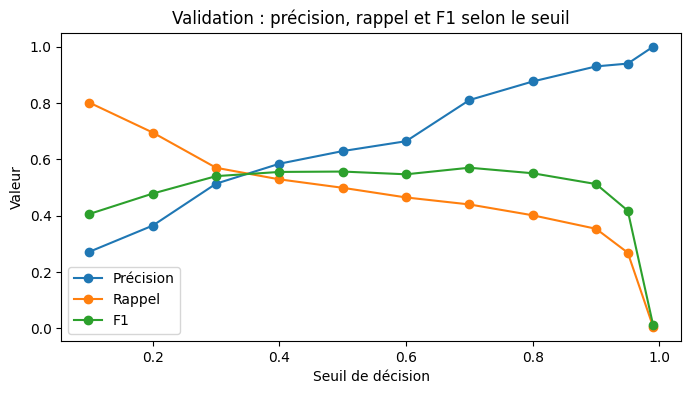

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(seuils["seuil"], seuils["precision"], marker="o", label="Précision")
plt.plot(seuils["seuil"], seuils["rappel"], marker="o", label="Rappel")
plt.plot(seuils["seuil"], seuils["f1"], marker="o", label="F1")
plt.xlabel("Seuil de décision")
plt.ylabel("Valeur")
plt.title("Validation : précision, rappel et F1 selon le seuil")
plt.legend()
plt.show()

Axe X : seuil de décision ; axe Y : valeur de la métrique. Quand le seuil monte, la précision augmente et le rappel baisse. Le F1 est le plus haut vers 0,7.

## 7. Sauvegarde du modèle et du seuil

In [12]:
meilleur_modele.write().overwrite().save("/workspace/data/modeles/modele_fraude")

with open("/workspace/data/modeles/seuil.txt", "w") as f:
    f.write(str(meilleur_seuil))

print("Modèle et seuil sauvegardés dans", "/workspace/data/modeles")

Modèle et seuil sauvegardés dans /workspace/data/modeles


In [13]:
spark.stop()